# Proyek Data Analytics: Kebiasaan Belajar dan Nilai Ujian

**Tujuan:** memeriksa kualitas data, merangkum statistik, membuat visualisasi, mengukur korelasi, dan menulis kesimpulan.

> Dataset ini adalah data sintetis (buatan) untuk latihan, bukan data mahasiswa sungguhan.


## 1. Pertanyaan analisis
1. Bagaimana gambaran umum nilai ujian?
2. Bagaimana rata-rata nilai ujian pada setiap kelompok jam belajar?
3. Seberapa kuat hubungan linear antara jam belajar dan nilai ujian?
4. Apa keterbatasan analisis ini?


## 2. Memuat library dan dataset
Pastikan file `dataset_kebiasaan_belajar.csv` berada di folder yang sama dengan notebook ini.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("dataset_kebiasaan_belajar.csv")
print("Ukuran dataset (baris, kolom):", df.shape)
df.head()


Ukuran dataset (baris, kolom): (50, 7)


,ID,Jam_Belajar,Kehadiran_Persen,Tugas_Selesai,Jam_Tidur,Nilai_Ujian,Lulus
0,1,2,95,8,7.5,78,Ya
1,2,1,80,6,6.0,62,Ya
2,3,4,100,10,8.0,91,Ya
3,4,3,90,9,7.0,84,Ya
4,5,0,70,4,5.5,48,Tidak


## 3. Memahami struktur dataset
`df.info()` menunjukkan tipe data dan jumlah nilai nonkosong. `df.describe()` merangkum statistik kolom numerik.


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                50 non-null     int64  
 1   Jam_Belajar       50 non-null     int64  
 2   Kehadiran_Persen  50 non-null     int64  
 3   Tugas_Selesai     50 non-null     int64  
 4   Jam_Tidur         50 non-null     float64
 5   Nilai_Ujian       50 non-null     int64  
 6   Lulus             50 non-null     str    
dtypes: float64(1), int64(5), str(1)
memory usage: 2.9 KB


In [3]:
df.describe().round(2)

,ID,Jam_Belajar,Kehadiran_Persen,Tugas_Selesai,Jam_Tidur,Nilai_Ujian
count,50.00,50.00,50.00,50.00,50.00,50.00
mean,25.50,2.24,85.56,7.18,6.75,72.48
std,14.58,1.53,11.09,2.22,0.95,17.67
min,1.00,0.00,60.00,3.00,5.00,38.00
25%,13.25,1.00,78.25,6.00,6.00,59.75
50%,25.50,2.00,87.50,7.50,7.00,73.50
75%,37.75,3.00,95.00,9.00,7.50,87.75
max,50.00,5.00,100.00,10.00,8.50,99.00


## 4. Data Cleaning dan validasi
Periksa nilai kosong, baris duplikat, tipe data, kategori status, dan rentang nilai dasar. Pemeriksaan ini tidak menjamin semua data benar secara substantif.


In [4]:
print("Missing values per kolom:")
display(df.isnull().sum())

print("Jumlah baris duplikat:", df.duplicated().sum())

print("\nTipe data:")
display(df.dtypes)

print("\nKategori kolom Lulus:")
print(df["Lulus"].value_counts(dropna=False))
print("Kategori unik:", df["Lulus"].unique())


Missing values per kolom:


ID                  0
Jam_Belajar         0
Kehadiran_Persen    0
Tugas_Selesai       0
Jam_Tidur           0
Nilai_Ujian         0
Lulus               0
dtype: int64

Jumlah baris duplikat: 0

Tipe data:


ID                    int64
Jam_Belajar           int64
Kehadiran_Persen      int64
Tugas_Selesai         int64
Jam_Tidur           float64
Nilai_Ujian           int64
Lulus                   str
dtype: object


Kategori kolom Lulus:
Lulus
Ya       37
Tidak    13
Name: count, dtype: int64
Kategori unik: <StringArray>
['Ya', 'Tidak']
Length: 2, dtype: str


In [5]:
checks = {
    "Jam belajar negatif": (df["Jam_Belajar"] < 0).sum(),
    "Kehadiran di luar 0-100": ((df["Kehadiran_Persen"] < 0) | (df["Kehadiran_Persen"] > 100)).sum(),
    "Tugas selesai negatif": (df["Tugas_Selesai"] < 0).sum(),
    "Jam tidur negatif": (df["Jam_Tidur"] < 0).sum(),
    "Nilai ujian di luar 0-100": ((df["Nilai_Ujian"] < 0) | (df["Nilai_Ujian"] > 100)).sum(),
    "Kategori Lulus selain Ya/Tidak": (~df["Lulus"].isin(["Ya", "Tidak"])).sum()
}
for nama, jumlah in checks.items():
    print(f"{nama}: {jumlah}")


Jam belajar negatif: 0
Kehadiran di luar 0-100: 0
Tugas selesai negatif: 0
Jam tidur negatif: 0
Nilai ujian di luar 0-100: 0
Kategori Lulus selain Ya/Tidak: 0


### Keputusan Data Cleaning
Jika pemeriksaan tidak menemukan masalah, jangan menghapus atau mengubah data tanpa alasan. Mempertahankan data juga keputusan Data Cleaning yang benar ketika data sudah lolos aturan pemeriksaan dasar.


## 5. Statistik deskriptif nilai ujian
Hitung rata-rata, median, standar deviasi, minimum, dan maksimum.


In [6]:
nilai = df["Nilai_Ujian"]
ringkasan_nilai = pd.DataFrame({
    "Metrik": ["Jumlah sampel", "Rata-rata", "Median", "Standar deviasi", "Minimum", "Maksimum"],
    "Nilai": [nilai.count(), nilai.mean(), nilai.median(), nilai.std(), nilai.min(), nilai.max()]
})
ringkasan_nilai.round(2)


,Metrik,Nilai
0,Jumlah sampel,50.00
1,Rata-rata,72.48
2,Median,73.50
3,Standar deviasi,17.67
4,Minimum,38.00
5,Maksimum,99.00


## 6. Membandingkan jam belajar dan nilai ujian
`groupby()` membagi data berdasarkan jam belajar, sedangkan `agg()` menghitung beberapa ringkasan untuk setiap kelompok.


In [7]:
hasil_per_jam = df.groupby("Jam_Belajar").agg(
    Jumlah_Sampel=("Nilai_Ujian", "count"),
    Rata_Rata_Nilai=("Nilai_Ujian", "mean"),
    Nilai_Minimum=("Nilai_Ujian", "min"),
    Nilai_Maksimum=("Nilai_Ujian", "max")
)
hasil_per_jam.round(2)


,Jumlah_Sampel,Rata_Rata_Nilai,Nilai_Minimum,Nilai_Maksimum
Jam_Belajar,,,,
0,8,43.88,38,49
1,9,59.33,53,65
2,12,72.25,66,79
3,9,83.33,73,92
4,8,91.50,88,95
5,4,97.50,96,99


## 7. Visualisasi

### 7.1 Grafik batang rata-rata nilai berdasarkan jam belajar


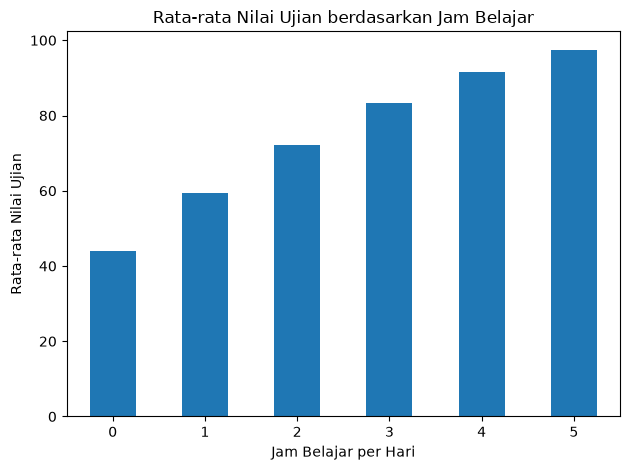

In [8]:
rata_per_jam = df.groupby("Jam_Belajar")["Nilai_Ujian"].mean()
rata_per_jam.plot(kind="bar")
plt.title("Rata-rata Nilai Ujian berdasarkan Jam Belajar")
plt.xlabel("Jam Belajar per Hari")
plt.ylabel("Rata-rata Nilai Ujian")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### 7.2 Scatter plot setiap sampel
Scatter plot memperlihatkan nilai tiap sampel terhadap jam belajar.


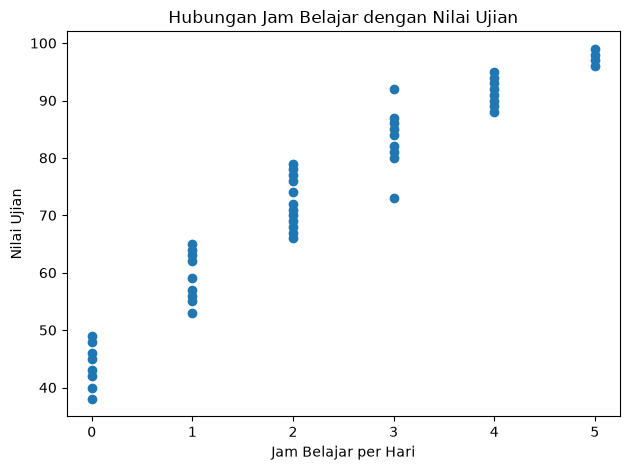

In [9]:
plt.scatter(df["Jam_Belajar"], df["Nilai_Ujian"])
plt.title("Hubungan Jam Belajar dengan Nilai Ujian")
plt.xlabel("Jam Belajar per Hari")
plt.ylabel("Nilai Ujian")
plt.tight_layout()
plt.show()


## 8. Korelasi
Korelasi Pearson mengukur arah dan kekuatan hubungan linear. Nilai dekat +1 menunjukkan hubungan positif kuat; dekat 0 menunjukkan hubungan linear lemah; dekat -1 menunjukkan hubungan negatif kuat. Korelasi bukan bukti sebab-akibat.


In [10]:
korelasi = df["Jam_Belajar"].corr(df["Nilai_Ujian"])
print(f"Korelasi Pearson jam belajar dan nilai ujian: {korelasi:.4f}")


Korelasi Pearson jam belajar dan nilai ujian: 0.9630


## 9. Kesimpulan berdasarkan hasil perhitungan
Cell berikut membuat ringkasan berdasarkan dataset yang sedang dimuat. Periksa apakah hasilnya cocok dengan tabel dan grafik.


In [11]:
rata_rata = df["Nilai_Ujian"].mean()
nilai_min = df["Nilai_Ujian"].min()
nilai_max = df["Nilai_Ujian"].max()
korelasi = df["Jam_Belajar"].corr(df["Nilai_Ujian"])
rata_per_jam = df.groupby("Jam_Belajar")["Nilai_Ujian"].mean()
jam_tertinggi = rata_per_jam.idxmax()
rata_tertinggi = rata_per_jam.max()

print("KESIMPULAN")
print(f"- Dataset berisi {len(df)} sampel dan {len(df.columns)} kolom.")
print(f"- Rata-rata nilai ujian: {rata_rata:.2f}; rentang nilai: {nilai_min:.0f}–{nilai_max:.0f}.")
print(f"- Rata-rata tertinggi ada pada kelompok {jam_tertinggi} jam belajar: {rata_tertinggi:.2f}.")
print(f"- Korelasi Pearson jam belajar dan nilai ujian: {korelasi:.4f}.")
if korelasi >= 0.7:
    print("- Hubungan linear yang teramati bersifat positif dan kuat dalam dataset ini.")
elif korelasi >= 0.3:
    print("- Hubungan linear yang teramati bersifat positif sedang dalam dataset ini.")
elif korelasi > 0:
    print("- Hubungan linear yang teramati bersifat positif tetapi lemah dalam dataset ini.")
elif korelasi <= -0.7:
    print("- Hubungan linear yang teramati bersifat negatif dan kuat dalam dataset ini.")
elif korelasi <= -0.3:
    print("- Hubungan linear yang teramati bersifat negatif sedang dalam dataset ini.")
else:
    print("- Hubungan linear yang teramati lemah atau mendekati nol dalam dataset ini.")
print("\nCatatan: korelasi tidak membuktikan sebab-akibat.")


KESIMPULAN
- Dataset berisi 50 sampel dan 7 kolom.
- Rata-rata nilai ujian: 72.48; rentang nilai: 38–99.
- Rata-rata tertinggi ada pada kelompok 5 jam belajar: 97.50.
- Korelasi Pearson jam belajar dan nilai ujian: 0.9630.
- Hubungan linear yang teramati bersifat positif dan kuat dalam dataset ini.

Catatan: korelasi tidak membuktikan sebab-akibat.


## 10. Keterbatasan analisis
1. **Data sintetis:** dibuat untuk latihan dan bukan dikumpulkan dari mahasiswa nyata.
2. **Ukuran sampel kecil:** hanya 50 sampel.
3. **Variabel terbatas:** metode belajar, kesulitan ujian, kondisi kesehatan, dan pengetahuan awal tidak tersedia.
4. **Korelasi bukan kausalitas:** hubungan yang terlihat tidak membuktikan jam belajar menyebabkan nilai meningkat.
5. **Pola bisa terbentuk saat pembuatan data:** korelasi kuat pada data buatan belum tentu muncul pada data nyata.
6. **Validasi dasar saja:** nilai yang masuk rentang wajar belum tentu benar secara konteks.

## 11. Kesimpulan akhir
Setelah menjalankan semua cell, tulis 1–2 paragraf berisi temuan utama, interpretasi yang tidak berlebihan, dan keterbatasan. Gunakan angka dari output aktual, bukan perkiraan.
